# figure 6
radiation only impact of sai on gpp, cesm2 g6 1.5k sai against ssp2 4.5 (results from 3_sai_regression)

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "pdf.fonttype": 42, "axes.titlelocation": "left"})
mm = 1 / 25.4
minus = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}".replace("-", "−"))
Path("figures").mkdir(exist_ok=True)
titles = {"US-Bi2": "US-Bi2 irrigated corn", "US-Ne1": "US-Ne1 irrigated maize", "US-Ne2": "US-Ne2 irrigated maize",
          "US-Ne3": "US-Ne3 rainfed maize", "US-xUN": "US-xUN mixed forest", "US-UMB": "US-UMB deciduous forest",
          "US-MMS": "US-MMS deciduous forest", "US-Ha1": "US-Ha1 deciduous forest"}
draws = pd.read_csv("results/sai_draws.csv")
point = pd.read_csv("results/sai_point.csv").set_index(["site", "component"]).pct
comps = [("light", "Less total light", "#E69F00"), ("diffuse", "More diffuse light", "#56B4E9"),
         ("radiation", "Net radiation effect", "#08306B")]

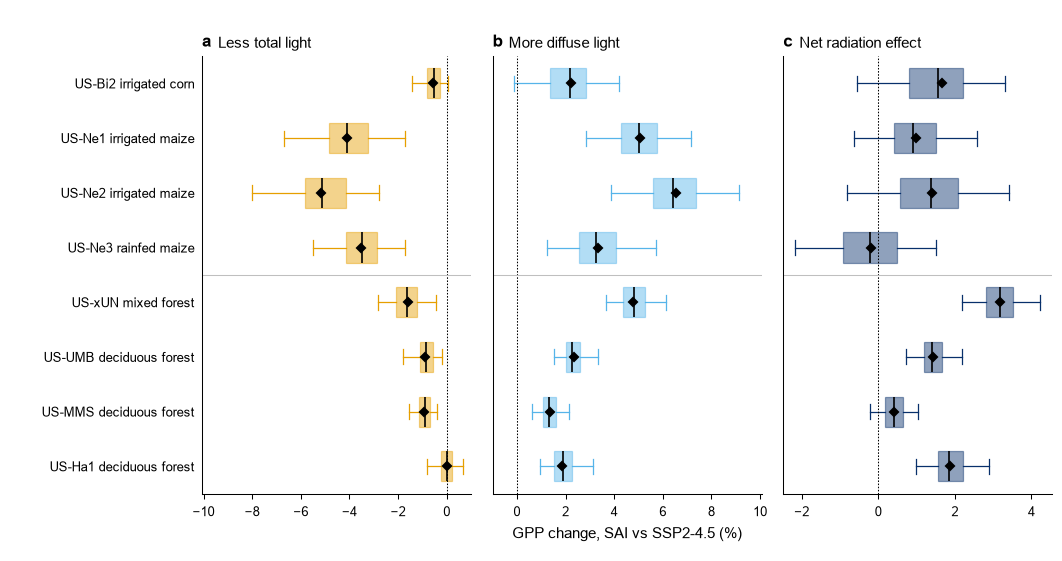

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(180 * mm, 95 * mm), sharey=True)
fig.subplots_adjust(left=0.19, right=0.99, top=0.9, bottom=0.12, wspace=0.08)
ys = np.arange(len(titles))[::-1]
for ax, (c, lab, col), letter in zip(axes, comps, "abc"):
    for y, site in zip(ys, titles):
        d = draws[draws.site == site][c]
        ax.bxp([dict(med=d.median(), q1=d.quantile(0.25), q3=d.quantile(0.75), whislo=d.quantile(0.025),
                     whishi=d.quantile(0.975), fliers=[])],
               positions=[y], orientation="horizontal", widths=0.55, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=col, alpha=0.45, edgecolor=col, lw=0.6), medianprops=dict(color="black", lw=0.8),
               whiskerprops=dict(color=col, lw=0.6), capprops=dict(color=col, lw=0.6))
        ax.plot(point[(site, c)], y, marker="D", ms=2.5, color="black", zorder=3)
    ax.axvline(0, color="black", lw=0.5, ls=(0, (1.5, 1.5)))
    ax.axhline(3.5, color="0.75", lw=0.5)
    ax.set_yticks(ys); ax.set_yticklabels(titles.values()); ax.tick_params(axis="y", length=0)
    ax.set_title(lab, loc="left", pad=4, x=0.06)
    ax.text(0.0, 1.0 + 4 / ax.bbox.height, letter, transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom")
    ax.xaxis.set_major_formatter(minus)
# light and diffuse panels on mirror image x axes
lim = 1.05 * max(abs(np.array(axes[0].get_xlim())).max(), abs(np.array(axes[1].get_xlim())).max())
axes[0].set_xlim(-lim, 1.0); axes[1].set_xlim(-1.0, lim)
axes[1].set_xlabel("GPP change, SAI vs SSP2-4.5 (%)")
fig.savefig("figures/fig6_sai_radiation.png", dpi=600)